<a href="https://colab.research.google.com/github/getuliojql/SISSA-CIN0114/blob/main/projeto/notebooks/01_reproducao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SISSA: Treinamento e Avaliação Completa
Configuração do ambiente, download do dataset e execução de todos os modelos (CNN, RNN, LSTM com e sem RSAB) variando o tamanho da janela.

## 0. Configuração do ambiente

### 0.1 Clonar o repositório
Clona o fork do grupo (`getuliojql/SISSA-CIN0114`), que contém o código original dos autores do SISSA mais as correções e extensões feitas pela equipe. A pasta de destino é forçada para `SISSA` para manter compatível com os caminhos (`%cd /content/SISSA`, imports, YAMLs) usados no restante do notebook, que foi originalmente escrito para o nome do repositório dos autores.

In [ ]:
!git clone https://github.com/getuliojql/SISSA-CIN0114.git SISSA

Cloning into 'SISSA'...
remote: Enumerating objects: 74, done.
remote: Counting objects: 100% (29/29), done.
remote: Compressing objects: 100% (28/28), done.
remote: Total 74 (delta 6), reused 16 (delta 1), pack-reused 45 (from 1)
Receiving objects: 100% (74/74), 983.09 KiB | 51.74 MiB/s, done.
Resolving deltas: 100% (15/15), done.


### 0.2 Baixar o dataset original
Baixa o arquivo compactado (`data.7z`) com o dataset SOME/IP gerado pelos autores do artigo (Liu et al., 2024), hospedado no Google Drive deles. Contém as janelas de tráfego já rotuladas (normal, 5 ataques, falha de hardware), usadas para reproduzir os resultados do artigo (Tabelas II a V).

In [ ]:
!gdown 'https://drive.google.com/uc?id=1-pl9OOFcTZCuPLRzusjlmkMn7Q-f-0fU'

Downloading...
From: https://drive.google.com/uc?id=1-pl9OOFcTZCuPLRzusjlmkMn7Q-f-0fU
To: /content/data.7z
100% 24.4M/24.4M [00:00<00:00, 151MB/s]


### 0.3 Extrair e posicionar os dados
Descompacta `data.7z` e move a pasta resultante para `SISSA/data/`, onde o código de pré-processamento (`preprocess/`) espera encontrar os arquivos `.npy` de treino e validação.

In [ ]:
!7z x data.7z
!mv data SISSA/data/


7-Zip 23.01 (x64) : Copyright (c) 1999-2023 Igor Pavlov : 2023-06-20
 64-bit locale=en_US.UTF-8 Threads:12 OPEN_MAX:1048576

Scanning the drive for archives:
  0M Scan         1 file, 24442938 bytes (24 MiB)

Extracting archive: data.7z
--
Path = data.7z
Type = 7z
Physical Size = 24442938
Headers Size = 407
Method = LZMA2:24
Solid = +
Blocks = 1

  0%     41% 5       81% 7 - data/processed/_2.npy                               98% 13 - data/train/data.npy                              99% 13 - data/train/data.npy                             Everything is Ok

Folders: 5
Files: 12
Size:       478261871
Compressed: 24442938


### 0.4 Instalar dependências adicionais
Instala bibliotecas Python que o ambiente do Colab não traz por padrão, mas que o código do SISSA usa: `ruamel.yaml` (leitura dos arquivos de configuração), `torchinfo` (contagem de parâmetros e tempo de inferência, usada na Tabela V) e `concurrent-log-handler` (dependência do sistema de logging do projeto).

In [ ]:
!pip install concurrent-log-handler==0.9.25 ruamel.yaml==0.17.21 torchinfo==1.8.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 109.5/109.5 kB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.7/129.7 kB 15.8 MB/s eta 0:00:00


### 0.5 Entrar na pasta do projeto
Muda o diretório de trabalho do Colab para `/content/SISSA`, onde estão os scripts (`train.py`, `test.py`, `initialize.py`) e os arquivos de configuração (`config/*.yml`) que as células seguintes importam e executam.

In [ ]:
%cd /content/SISSA

/content/SISSA


## 1. Treinamento e Teste (Todos os Modelos e Tamanhos de Janela)
Treina e avalia `SISSA-C`, `SISSA-C-A`, `SISSA-R`, `SISSA-R-A`, `SISSA-L` e `SISSA-L-A` para janelas `w32` a `w128`.

### 1.1 Treinar e testar todas as combinações
Para cada tamanho de janela (`w32` a `w128`) e cada uma das 6 variantes do modelo (`SISSA-C`, `SISSA-C-A`, `SISSA-R`, `SISSA-R-A`, `SISSA-L`, `SISSA-L-A`), esta célula: (1) ajusta o `config/basic.yml` e o YAML do modelo; (2) treina por 150 épocas, conforme a Seção V-B do artigo; (3) avalia com o melhor checkpoint salvo; (4) mede parâmetros, memória e tempo de inferência (insumo da Tabela V). É a célula mais demorada do notebook — gera os dados usados por todas as tabelas e figuras seguintes.

In [ ]:
import sys
import os
import importlib.util

import time
import torch
import torchinfo
import numpy as np
import matplotlib.pyplot as plt
from ruamel.yaml import YAML

import initialize
import sissautils
from models import SISSA_MODELS
from train import train_pattern

# Dynamically import the local test module to bypass conflict with Python's built-in 'test'
spec = importlib.util.spec_from_file_location("local_test", "test.py")
local_test = importlib.util.module_from_spec(spec)
sys.modules["local_test"] = local_test
spec.loader.exec_module(local_test)
test_pattern = local_test.test_pattern

yaml = YAML()
initialize.init()

MODELS = ["SISSA-C", "SISSA-C-A", "SISSA-R", "SISSA-R-A", "SISSA-L", "SISSA-L-A"]
WINDOW_SIZES = [32, 48, 64, 80, 96, 112, 128]
EPOCHS = 150  # Conforme seo V-B do artigo

def get_best_checkpoint(weights_dir):
    pts = [f for f in os.listdir(weights_dir) if f.endswith(".pt")]
    pts.sort(key=lambda f: (float(f[:-3].split("val-acc-")[1]), int(f.split("_")[0].split("-")[1])))
    return os.path.join(weights_dir, pts[-1])

overhead_records = []

for w in WINDOW_SIZES:
    # Atualiza tamanho da janela no basic.yml
    basic_cfg = yaml.load(open("config/basic.yml", "r"))
    basic_cfg["Preprocessor"]["window_height"] = w
    yaml.dump(basic_cfg, open("config/basic.yml", "w"))

    for m_name in MODELS:
        cfg_path = f"config/{m_name}.yml"
        run_name = f"{m_name}_w{w}"
        print(f"\n==================== {run_name} ====================")

        # Atualiza configurao do modelo
        m_cfg = yaml.load(open(cfg_path, "r"))
        m_cfg["Model"]["name"] = run_name
        m_cfg["Train"]["epochs"] = EPOCHS
        yaml.dump(m_cfg, open(cfg_path, "w"))

        # Treinamento
        m_cfg = sissautils.update_model_config(model_config_path=cfg_path)
        model = SISSA_MODELS[m_cfg["Model"]["type"]](**m_cfg["Params"])
        hparams = sissautils.hyperparams(model_config=m_cfg, model=model)
        train_pattern(**hparams)

        # Teste com o melhor checkpoint
        best_pt = get_best_checkpoint(hparams["weights_dir"])
        test_pattern(model_config_path=cfg_path, weights_path=best_pt)
        plt.close("all")

        # Coleta de mtricas computacionais (Tabela V)
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        model.load_state_dict(torch.load(best_pt, map_location=device))
        model = model.to(device).eval()
        stats = torchinfo.summary(
            model, input_size=(w, m_cfg["Params"]["pack_dim"]), verbose=0
        )
        test_loader = sissautils.to_dataloader(
            m_cfg["Test"]["test_dir"], 1, 1, False, logger_name="Test"
        )
        t_cost = 0.0
        with torch.no_grad():
            for data, _ in test_loader:
                t0 = time.time()
                _ = model(data.to(device))
                t_cost += time.time() - t0
        overhead_records.append({
            "Windows": f"w{w}",
            "Model": m_name,
            "Total Params": stats.total_params,
            "Params size (MB)": round(stats.total_param_bytes / 1e6, 2),
            "Input size (MB)": round(stats.total_input / 1e6, 2),
            "Forward/Backward Pass size (MB)": round(stats.total_output_bytes / 1e6, 2),
            "Total size (MB)": round((stats.total_input + stats.total_output_bytes + stats.total_param_bytes) / 1e6, 2),
            "Time Cost (s)": round(t_cost / len(test_loader), 4),
        })

[to_dataloader][CRITICAL] >>>>> Sending data to dataloader...
CRITICAL:Train:Sending data to dataloader...
[to_dataloader][INFO] >>>>> Loaded data from data/train/data.npy, shape: (14406, 32, 25)
INFO:Train:Loaded data from data/train/data.npy, shape: (14406, 32, 25)
[to_dataloader][INFO] >>>>> Loaded label from data/train/labels.npy, shape: (14406,)
INFO:Train:Loaded label from data/train/labels.npy, shape: (14406,)
[to_dataloader][CRITICAL] >>>>> Data sent to dataloader.
CRITICAL:Train:Data sent to dataloader.
[to_dataloader][CRITICAL] >>>>> Sending data to dataloader...
CRITICAL:Train:Sending data to dataloader...
[to_dataloader][INFO] >>>>> Loaded data from data/val/data.npy, shape: (3605, 32, 25)
INFO:Train:Loaded data from data/val/data.npy, shape: (3605, 32, 25)
[to_dataloader][INFO] >>>>> Loaded label from data/val/labels.npy, shape: (3605,)
INFO:Train:Loaded label from data/val/labels.npy, shape: (3605,)
[to_dataloader][CRITICAL] >>>>> Data sent to dataloader.
CRITICAL:Train:D


==================== SISSA-C_w32 ====================


[train_pattern][CRITICAL] >>>>> Start training...
CRITICAL:Train:Start training...
[train_pattern][INFO] >>>>> Epoch:    1 | Train acc: 0.1567, Val acc: 0.1545
INFO:Train:Epoch:    1 | Train acc: 0.1567, Val acc: 0.1545
[train_pattern][INFO] >>>>> Epoch:    2 | Train acc: 0.1755, Val acc: 0.1847
INFO:Train:Epoch:    2 | Train acc: 0.1755, Val acc: 0.1847
[train_pattern][INFO] >>>>> Epoch:    3 | Train acc: 0.1985, Val acc: 0.1914
INFO:Train:Epoch:    3 | Train acc: 0.1985, Val acc: 0.1914
[train_pattern][INFO] >>>>> Epoch:    4 | Train acc: 0.2054, Val acc: 0.1964
INFO:Train:Epoch:    4 | Train acc: 0.2054, Val acc: 0.1964
[train_pattern][INFO] >>>>> Epoch:    5 | Train acc: 0.2144, Val acc: 0.1933
INFO:Train:Epoch:    5 | Train acc: 0.2144, Val acc: 0.1933
[train_pattern][INFO] >>>>> Epoch:    6 | Train acc: 0.2132, Val acc: 0.1945
INFO:Train:Epoch:    6 | Train acc: 0.2132, Val acc: 0.1945
[train_pattern][INFO] >>>>> Epoch:    7 | Train acc: 0.2175, Val acc: 0.1942
INFO:Train:Epoch: 


==================== SISSA-C-A_w32 ====================


[train_pattern][INFO] >>>>> Epoch:    1 | Train acc: 0.1728, Val acc: 0.1867
INFO:Train:Epoch:    1 | Train acc: 0.1728, Val acc: 0.1867
[train_pattern][INFO] >>>>> Epoch:    2 | Train acc: 0.2020, Val acc: 0.1983
INFO:Train:Epoch:    2 | Train acc: 0.2020, Val acc: 0.1983
[train_pattern][INFO] >>>>> Epoch:    3 | Train acc: 0.2090, Val acc: 0.2039
INFO:Train:Epoch:    3 | Train acc: 0.2090, Val acc: 0.2039
[train_pattern][INFO] >>>>> Epoch:    4 | Train acc: 0.2149, Val acc: 0.2094
INFO:Train:Epoch:    4 | Train acc: 0.2149, Val acc: 0.2094
[train_pattern][INFO] >>>>> Epoch:    5 | Train acc: 0.2200, Val acc: 0.2108
INFO:Train:Epoch:    5 | Train acc: 0.2200, Val acc: 0.2108
[train_pattern][INFO] >>>>> Epoch:    6 | Train acc: 0.2201, Val acc: 0.2161
INFO:Train:Epoch:    6 | Train acc: 0.2201, Val acc: 0.2161
[train_pattern][INFO] >>>>> Epoch:    7 | Train acc: 0.2321, Val acc: 0.2155
INFO:Train:Epoch:    7 | Train acc: 0.2321, Val acc: 0.2155
[train_pattern][INFO] >>>>> Epoch:    8 |


==================== SISSA-R_w32 ====================


... (75 outputs left out)


==================== SISSA-L_w128 ====================


[train_pattern][INFO] >>>>> Epoch:    1 | Train acc: 0.4413, Val acc: 0.5889
INFO:Train:Epoch:    1 | Train acc: 0.4413, Val acc: 0.5889
[train_pattern][INFO] >>>>> Epoch:    2 | Train acc: 0.6488, Val acc: 0.7068
INFO:Train:Epoch:    2 | Train acc: 0.6488, Val acc: 0.7068
[train_pattern][INFO] >>>>> Epoch:    3 | Train acc: 0.8149, Val acc: 0.6921
INFO:Train:Epoch:    3 | Train acc: 0.8149, Val acc: 0.6921
[train_pattern][INFO] >>>>> Epoch:    4 | Train acc: 0.8483, Val acc: 0.9026
INFO:Train:Epoch:    4 | Train acc: 0.8483, Val acc: 0.9026
[train_pattern][INFO] >>>>> Epoch:    5 | Train acc: 0.9315, Val acc: 0.9481
INFO:Train:Epoch:    5 | Train acc: 0.9315, Val acc: 0.9481
[train_pattern][INFO] >>>>> Epoch:    6 | Train acc: 0.9322, Val acc: 0.9448
INFO:Train:Epoch:    6 | Train acc: 0.9322, Val acc: 0.9448
[train_pattern][INFO] >>>>> Epoch:    7 | Train acc: 0.9613, Val acc: 0.9584
INFO:Train:Epoch:    7 | Train acc: 0.9613, Val acc: 0.9584
[train_pattern][INFO] >>>>> Epoch:    8 |


==================== SISSA-L-A_w128 ====================


[train_pattern][INFO] >>>>> Epoch:    1 | Train acc: 0.4544, Val acc: 0.5895
INFO:Train:Epoch:    1 | Train acc: 0.4544, Val acc: 0.5895
[train_pattern][INFO] >>>>> Epoch:    2 | Train acc: 0.6492, Val acc: 0.7498
INFO:Train:Epoch:    2 | Train acc: 0.6492, Val acc: 0.7498
[train_pattern][INFO] >>>>> Epoch:    3 | Train acc: 0.7527, Val acc: 0.6092
INFO:Train:Epoch:    3 | Train acc: 0.7527, Val acc: 0.6092
[train_pattern][INFO] >>>>> Epoch:    4 | Train acc: 0.8306, Val acc: 0.8913
INFO:Train:Epoch:    4 | Train acc: 0.8306, Val acc: 0.8913
[train_pattern][INFO] >>>>> Epoch:    5 | Train acc: 0.8829, Val acc: 0.8438
INFO:Train:Epoch:    5 | Train acc: 0.8829, Val acc: 0.8438
[train_pattern][INFO] >>>>> Epoch:    6 | Train acc: 0.9254, Val acc: 0.9420
INFO:Train:Epoch:    6 | Train acc: 0.9254, Val acc: 0.9420
[train_pattern][INFO] >>>>> Epoch:    7 | Train acc: 0.8966, Val acc: 0.9426
INFO:Train:Epoch:    7 | Train acc: 0.8966, Val acc: 0.9426
[train_pattern][INFO] >>>>> Epoch:    8 |

## 2. Gráficos e Tabelas do Artigo

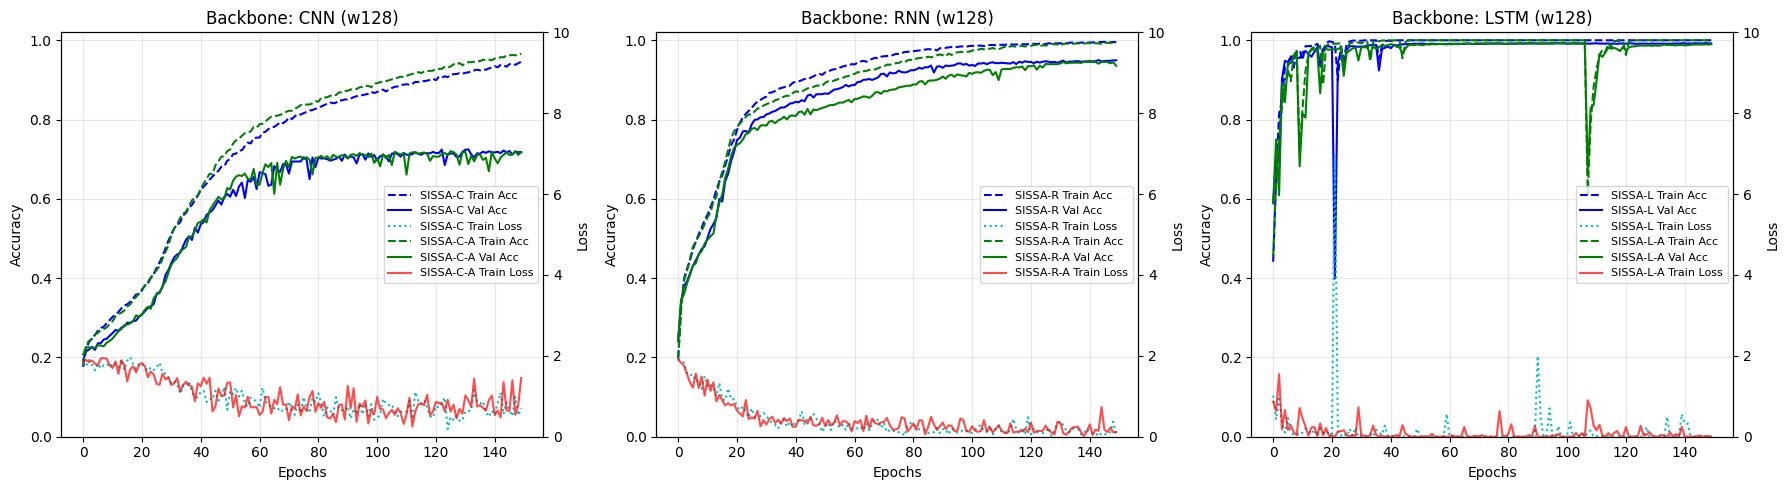

In [ ]:
# Figura 9: Curvas de Acurácia (Treino/Validação) e Loss por época (w128)
target_w = WINDOW_SIZES[-1]
groups = [
    ("CNN", "SISSA-C", "SISSA-C-A"),
    ("RNN", "SISSA-R", "SISSA-R-A"),
    ("LSTM", "SISSA-L", "SISSA-L-A"),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax1, (title, m_base, m_att) in zip(axes, groups):
    log_b = f"results/train_log/{m_base}_w{target_w}"
    log_a = f"results/train_log/{m_att}_w{target_w}"

    tr_acc_b = np.load(f"{log_b}/train_accs.npy")
    val_acc_b = np.load(f"{log_b}/val_accs.npy")
    loss_b = np.load(f"{log_b}/train_losses.npy")

    tr_acc_a = np.load(f"{log_a}/train_accs.npy")
    val_acc_a = np.load(f"{log_a}/val_accs.npy")
    loss_a = np.load(f"{log_a}/train_losses.npy")

    epochs_x = range(len(loss_b))
    ax2 = ax1.twinx()

    l1, = ax1.plot(epochs_x, tr_acc_b, "b--", label=f"{m_base} Train Acc")
    l2, = ax1.plot(epochs_x, val_acc_b, "b-", label=f"{m_base} Val Acc")
    l3, = ax2.plot(epochs_x, loss_b, "c:", label=f"{m_base} Train Loss")

    l4, = ax1.plot(epochs_x, tr_acc_a, "g--", label=f"{m_att} Train Acc")
    l5, = ax1.plot(epochs_x, val_acc_a, "g-", label=f"{m_att} Val Acc")
    l6, = ax2.plot(epochs_x, loss_a, "r-", alpha=0.7, label=f"{m_att} Train Loss")

    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Accuracy")
    ax1.set_ylim(0, 1.02)
    ax2.set_ylabel("Loss")
    ax2.set_ylim(0, 10)
    ax1.set_title(f"Backbone: {title} (w{target_w})")
    ax1.grid(True, alpha=0.3)
    ax1.legend(handles=[l1, l2, l3, l4, l5, l6], loc="center right", fontsize=8)

plt.tight_layout()
plt.show()

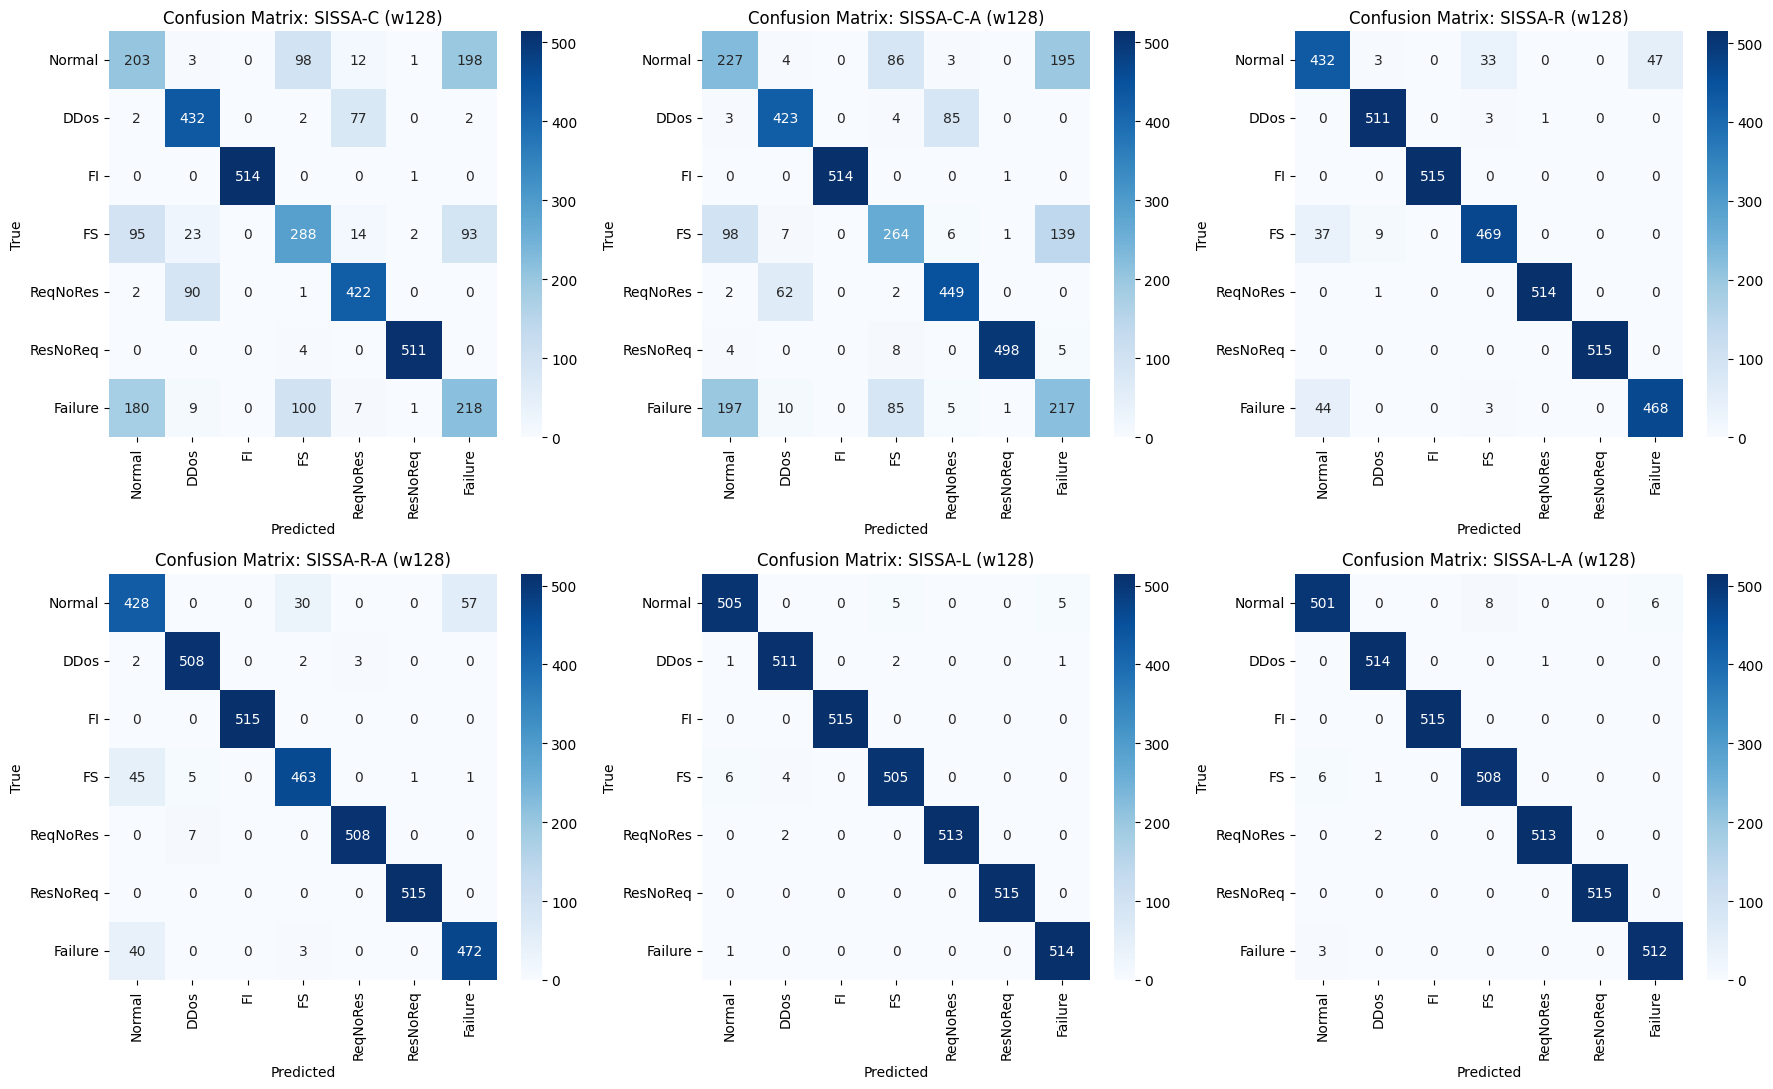

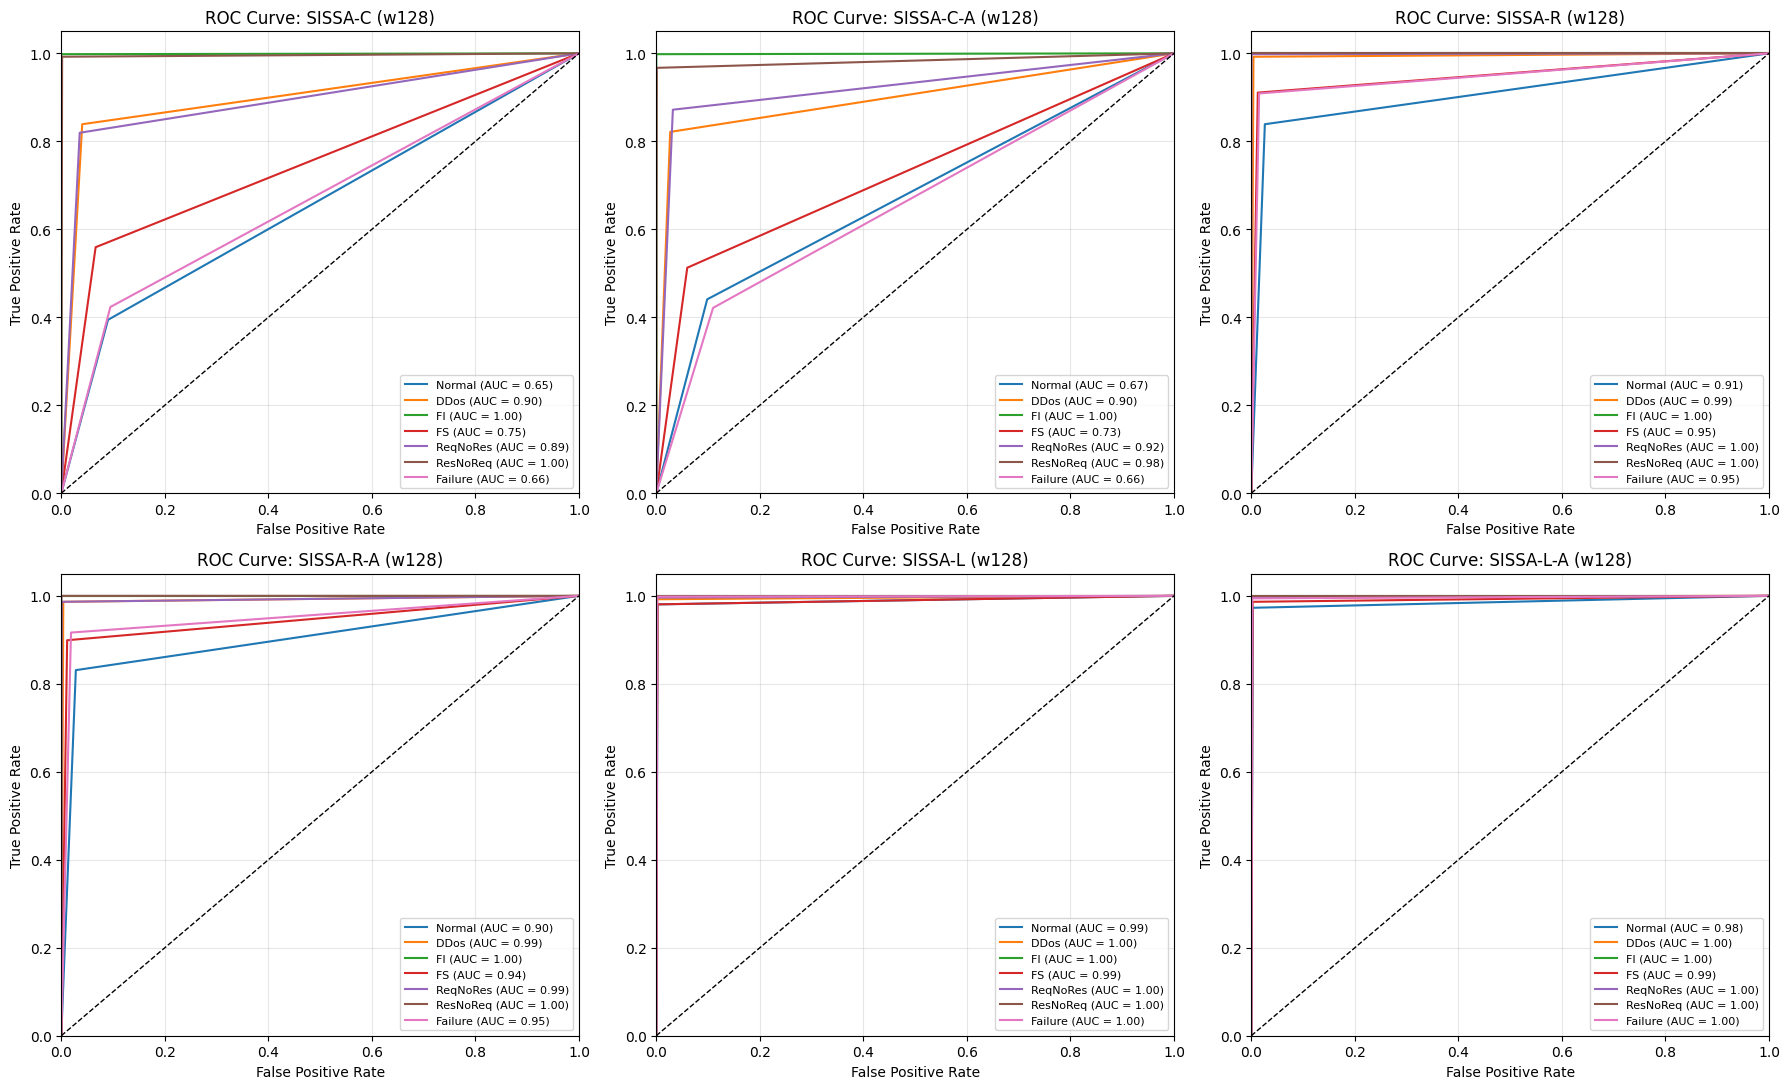

In [ ]:
# Figuras 10 e 11: Matrizes de Confusão e Curvas ROC / AUC para os 6 modelos (w128)
import seaborn as sns
from sklearn.metrics import roc_curve, auc

basic_cfg = yaml.load(open("config/basic.yml", "r"))
class_names = basic_cfg["Preprocessor"]["class_names"]
n_classes = len(class_names)

# Figura 10: Matrizes de Confusão
fig_cm, axes_cm = plt.subplots(2, 3, figsize=(18, 11))
for ax, m_name in zip(axes_cm.flat, MODELS):
    cm = np.load(f"results/test_result/{m_name}_w{target_w}/cm.npy")
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(f"Confusion Matrix: {m_name} (w{target_w})")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
plt.tight_layout()
plt.show()

# Figura 11: Curvas ROC e AUC
fig_roc, axes_roc = plt.subplots(2, 3, figsize=(18, 11))
for ax, m_name in zip(axes_roc.flat, MODELS):
    res_dir = f"results/test_result/{m_name}_w{target_w}"
    y_true = np.load(f"{res_dir}/true.npy")
    y_pred = np.load(f"{res_dir}/pred.npy")

    for c_idx, c_name in enumerate(class_names):
        fpr, tpr, _ = roc_curve((y_true == c_idx).astype(int), (y_pred == c_idx).astype(int))
        roc_auc = auc(fpr, tpr)
        ax.plot(fpr, tpr, label=f"{c_name} (AUC = {roc_auc:.2f})")

    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(f"ROC Curve: {m_name} (w{target_w})")
    ax.legend(loc="lower right", fontsize=8)
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

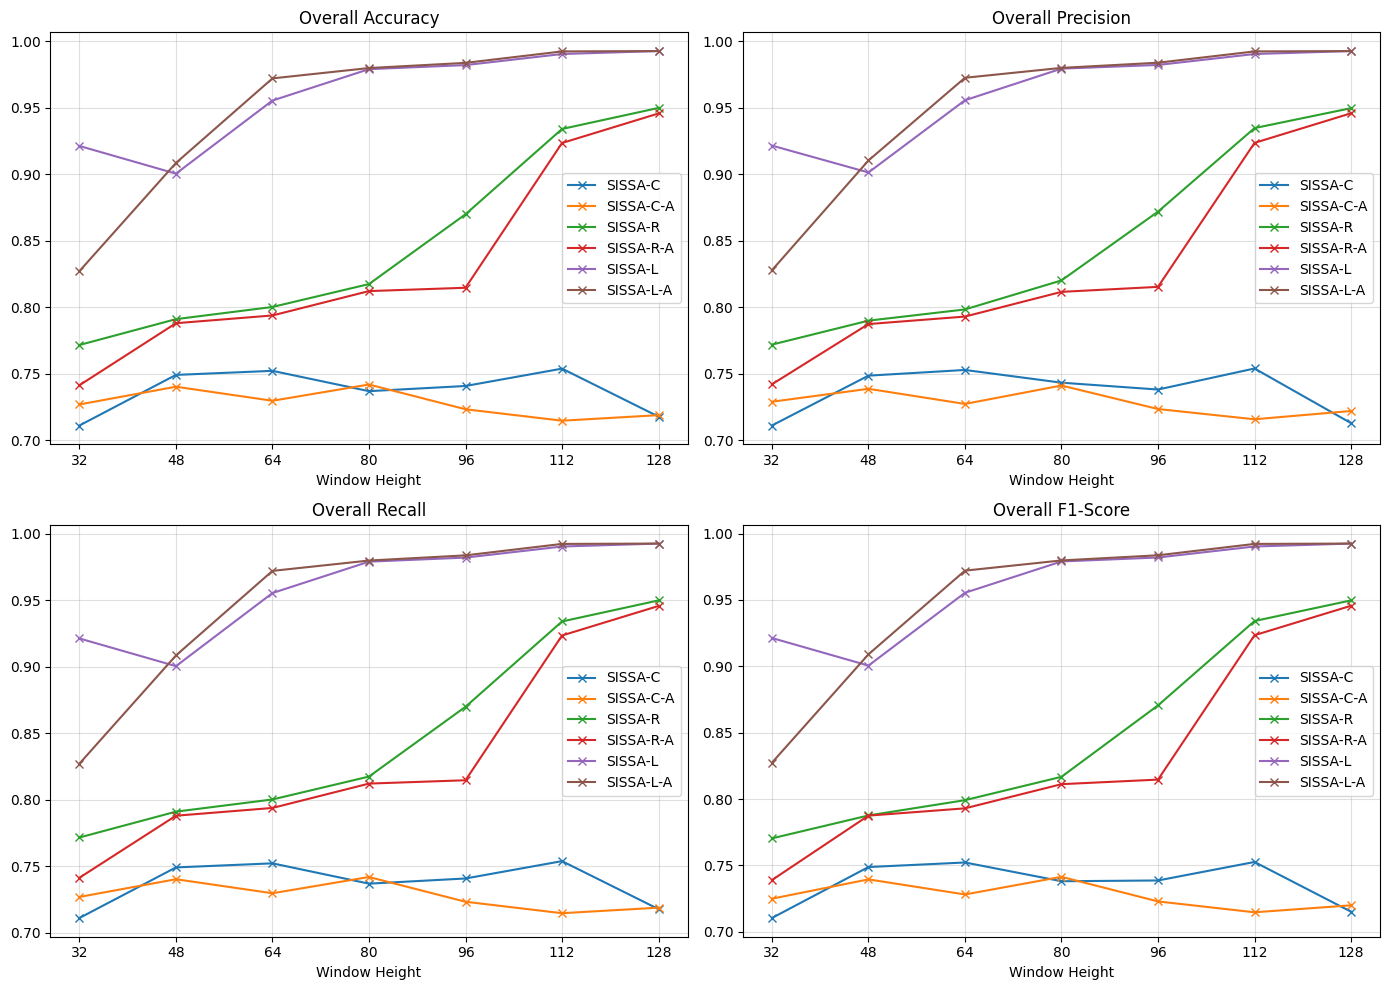

In [ ]:
# Figura 12: Accuracy, Precision, Recall e F1-Score variando o tamanho da janela
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

metrics_by_w = {metric: {m: [] for m in MODELS} for metric in ["Overall Accuracy", "Overall Precision", "Overall Recall", "Overall F1-Score"]}

for w in WINDOW_SIZES:
    for m_name in MODELS:
        res_dir = f"results/test_result/{m_name}_w{w}"
        y_true = np.load(f"{res_dir}/true.npy")
        y_pred = np.load(f"{res_dir}/pred.npy")
        metrics_by_w["Overall Accuracy"][m_name].append(accuracy_score(y_true, y_pred))
        metrics_by_w["Overall Precision"][m_name].append(precision_score(y_true, y_pred, average="macro", zero_division=0))
        metrics_by_w["Overall Recall"][m_name].append(recall_score(y_true, y_pred, average="macro", zero_division=0))
        metrics_by_w["Overall F1-Score"][m_name].append(f1_score(y_true, y_pred, average="macro", zero_division=0))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (metric_name, m_dict) in zip(axes.flat, metrics_by_w.items()):
    for m_name in MODELS:
        ax.plot(WINDOW_SIZES, m_dict[m_name], marker="x", label=m_name)
    ax.set_title(metric_name)
    ax.set_xlabel("Window Height")
    ax.set_xticks(WINDOW_SIZES)
    ax.grid(True, alpha=0.4)
    ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Tabelas III, IV e V do artigo
import pandas as pd
from IPython.display import display

def binary_metrics(y_true_bin, y_pred_bin):
    tp = np.sum((y_true_bin == 1) & (y_pred_bin == 1))
    tn = np.sum((y_true_bin == 0) & (y_pred_bin == 0))
    fp = np.sum((y_true_bin == 0) & (y_pred_bin == 1))
    fn = np.sum((y_true_bin == 1) & (y_pred_bin == 0))
    acc = (tp + tn) / (tp + tn + fp + fn)
    pre = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = (2 * pre * rec) / (pre + rec) if (pre + rec) > 0 else 0.0
    return round(acc, 3), round(pre, 3), round(rec, 3), round(f1, 3)

rows_t3, rows_t4 = [], []
for m_name in MODELS:
    res_dir = f"results/test_result/{m_name}_w{target_w}"
    y_true = np.load(f"{res_dir}/true.npy")
    y_pred = np.load(f"{res_dir}/pred.npy")

    # Tabela III: Normal (0), Attack (1..5), Failure (6)
    y_t3 = np.where(y_true == 0, 0, np.where(y_true == 6, 2, 1))
    p_t3 = np.where(y_pred == 0, 0, np.where(y_pred == 6, 2, 1))
    for idx, cname in enumerate(["Normal", "Attack", "Failure"]):
        acc, pre, rec, f1 = binary_metrics((y_t3 == idx).astype(int), (p_t3 == idx).astype(int))
        rows_t3.append({"Model": m_name, "Class": cname, "Acc": acc, "Pre": pre, "Recall": rec, "F1": f1})

    # Tabela IV: Todas as 7 classes
    for idx, cname in enumerate(class_names):
        acc, pre, rec, f1 = binary_metrics((y_true == idx).astype(int), (y_pred == idx).astype(int))
        rows_t4.append({"Model": m_name, "Class": cname, "Acc": acc, "Pre": pre, "Recall": rec, "F1": f1})

print(f"=== Tabela III: Comparação por Categoria (w{target_w}) ===")
display(pd.DataFrame(rows_t3))

print(f"\n=== Tabela IV: Comparação por Classe (w{target_w}) ===")
display(pd.DataFrame(rows_t4))

print("\n=== Tabela V: Características e Recursos Computacionais ===")
display(pd.DataFrame(overhead_records))

=== Tabela III: Comparação por Categoria (w128) ===


,Model,Class,Acc,Pre,Recall,F1
0,SISSA-C,Normal,0.836,0.421,0.394,0.407
1,SISSA-C,Attack,0.882,0.912,0.925,0.918
2,SISSA-C,Failure,0.836,0.427,0.423,0.425
3,SISSA-C-A,Normal,0.836,0.427,0.441,0.434
4,SISSA-C-A,Attack,0.877,0.923,0.903,0.913
5,SISSA-C-A,Failure,0.823,0.390,0.421,0.405
6,SISSA-R,Normal,0.955,0.842,0.839,0.840
7,SISSA-R,Attack,0.979,0.985,0.986,0.985
8,SISSA-R,Failure,0.974,0.909,0.909,0.909
9,SISSA-R-A,Normal,0.952,0.831,0.831,0.831



=== Tabela IV: Comparação por Classe (w128) ===


,Model,Class,Acc,Pre,Recall,F1
0,SISSA-C,Normal,0.836,0.421,0.394,0.407
1,SISSA-C,DDos,0.942,0.776,0.839,0.806
2,SISSA-C,FI,1.000,1.000,0.998,0.999
3,SISSA-C,FS,0.880,0.584,0.559,0.571
4,SISSA-C,ReqNoRes,0.944,0.793,0.819,0.806
5,SISSA-C,ResNoReq,0.998,0.990,0.992,0.991
6,SISSA-C,Failure,0.836,0.427,0.423,0.425
7,SISSA-C-A,Normal,0.836,0.427,0.441,0.434
8,SISSA-C-A,DDos,0.951,0.836,0.821,0.829
9,SISSA-C-A,FI,1.000,1.000,0.998,0.999



=== Tabela V: Características e Recursos Computacionais ===


,Windows,Model,Total Params,Params size (MB),Input size (MB),Forward/Backward Pass size (MB),Total size (MB),Time Cost (s)
0,w32,SISSA-C,73352,0.29,0.00,1.00,1.29,0.0008
1,w32,SISSA-C-A,74168,0.30,0.00,1.00,1.30,0.0012
2,w32,SISSA-R,579911,2.32,0.00,0.07,2.40,0.0008
3,w32,SISSA-R-A,629447,2.52,0.00,0.17,2.69,0.0012
4,w32,SISSA-L,2923335,11.69,0.00,0.14,11.84,0.0016
5,w32,SISSA-L-A,3120711,12.48,0.00,0.34,12.82,0.0020
6,w48,SISSA-C,73768,0.30,0.00,1.01,1.31,0.0009
7,w48,SISSA-C-A,74584,0.30,0.00,1.01,1.31,0.0013
8,w48,SISSA-R,844519,3.38,0.00,0.12,3.50,0.0008
9,w48,SISSA-R-A,894055,3.58,0.00,0.27,3.85,0.0012


## 3. Salvar os Resultados

In [ ]:
from google.colab import drive
import os
import shutil

# 1. Montar o Google Drive
drive.mount('/content/drive')

# 2. Definir os caminhos de origem e destino
origem = '/content/SISSA/results'
destino = '/content/drive/MyDrive/SISSA_results'

# 3. Copiar a pasta de forma recursiva
if os.path.exists(origem):
    if os.path.exists(destino):
        # Se já existir, remove para atualizar com os novos dados
        shutil.rmtree(destino)
    shutil.copytree(origem, destino)
    print(f"Sucesso! Pasta copiada para: {destino}")
else:
    print(f"Erro: A pasta de origem {origem} não foi encontrada.")

Mounted at /content/drive
Sucesso! Pasta copiada para: /content/drive/MyDrive/SISSA_results
